# Türk Sineması Oyuncu Ağı — Zamansal Küçük Dünya Analizi
**Araştırma sorusu:** Türk sineması bir "küçük dünya" mı? Yeşilçam'dan bugüne ağın yapısı nasıl değişti?

Bu defter `src/` altındaki script'leri sırayla çalıştırır ve ana sonuçları gösterir. Tüm rastgele işlemler sabit tohumla yapılır (`SEED = 42`, `src/ortak.py`); aynı veriyle her çalıştırma aynı sonucu verir.

In [1]:
import os, sys, json, subprocess
from pathlib import Path
import pandas as pd
from IPython.display import Image, display
KOK = Path.cwd()
SRC = KOK / "src"
sys.path.insert(0, str(SRC))
from ortak import SEED
print("SEED =", SEED)
os.environ["N_NULL"] = "100"   # null model: 100 rastgele ağ
os.environ["N_RAND"] = "100"   # zamansal analiz: her on yıl için 100 rastgele referans ağ
def calistir(script):
    r = subprocess.run([sys.executable, script], cwd=SRC, capture_output=True, text=True, env=os.environ)
    print(r.stdout[-4000:]); 
    if r.returncode: print(r.stderr[-4000:]); raise RuntimeError(script)
pd.set_option("display.width", 200)

SEED = 42


## 1. Veri toplama (`01_veri_topla.py`)
Wikidata SPARQL'den Türk yapımı filmler (P31/P279* Q11424, P495 = Q43), yayın yılı (P577'nin en erken yılı, 1950–2025) ve oyuncular (P161) çekilir. Hız sınırına uymak için istekler arası bekleme ve tanımlayıcı User-Agent kullanılır.

Not: Bu adım ağ erişimi gerektirir; ham veri öğrencinin bilgisayarında bu script ile toplanmıştır. `data/raw` doluysa yeniden çekilmez (sonuçların tekrarlanabilirliği için toplanan anlık görüntü kullanılır).

In [2]:
raw = KOK / "data" / "raw"
if not (raw / "film_oyuncu.csv").exists():
    calistir("01_veri_topla.py")
else:
    print("veri mevcut")
print(json.dumps(json.loads((raw / "toplama_bilgisi.json").read_text(encoding="utf-8")), ensure_ascii=False, indent=2))

veri mevcut
{
  "toplama_zamani_utc": "2026-10-29T18:19:25+00:00",
  "kaynak": "https://query.wikidata.org/sparql",
  "lisans": "Wikidata verisi CC0 1.0 (kamu malı) lisanslıdır",
  "film_tanimi": "P31/P279* Q11424 ve P495 = Q43",
  "yil_araligi": [
    1950,
    2025
  ],
  "film_sayisi_tum": 3652,
  "film_sayisi_yilli_aralikta": 2961,
  "yili_olmayan_film": 602,
  "p161_olan_film": 1954,
  "film_oyuncu_satiri": 6099,
  "benzersiz_oyuncu": 2070
}


## 2. Ağ kurma (`02_ag_kur.py`)
- **İki parçalı ağ:** film ↔ oyuncu.
- **Projeksiyon:** iki oyuncu aynı filmde oynadıysa aralarında kenar vardır. **Yönsüz** (birlikte oynamak simetriktir), **ağırlık = ortak film sayısı** (tekrarlanan iş birliği daha güçlü bağdır).
- Çıktılar: `data/processed/kenar_listesi.csv`, `dugumler.csv`, `oyuncu_agi.graphml`, `iki_parcali_ag.graphml`.

In [3]:
calistir("02_ag_kur.py")
pd.read_csv(KOK/"data/processed/kenar_listesi.csv").head()

İki parçalı ağ: 1954 film, 2070 oyuncu, 6099 bağ
Oyuncu ağı: 2070 düğüm, 16073 kenar, yoğunluk 0.007506, bileşen 125



,kaynak,hedef,kaynak_adi,hedef_adi,agirlik,ilk_yil,son_yil
0,Q100240,Q113604995,Meral Perin,Beritan Balci,1,2025,2025
1,Q100240,Q19936977,Meral Perin,Serkan Çayoğlu,1,2025,2025
2,Q100240,Q19960028,Meral Perin,Anja Karmanski,1,2025,2025
3,Q100240,Q62346,Meral Perin,Katja Riemann,1,2025,2025
4,Q100977816,Q102317186,Milan Mikulčík,Marta Dancingerová,1,2025,2025


## 3. Temel ölçüler (`03_temel_olculer.py`)
Yoğunluk, bileşenler, ortalama en kısa yol ve çap (dev bileşen, tam hesap), kümelenme, derece benzeşimi; derece dağılımının `powerlaw` paketiyle kuvvet yasası ve alternatif dağılımlarla karşılaştırılması; derece, betweenness, closeness, eigenvector ve PageRank merkeziyetleri, ilk-10 tabloları ve Spearman korelasyonu. Topoloji ölçüleri ağırlıksız hesaplanır.

In [4]:
calistir("03_temel_olculer.py")
t = json.loads((KOK/"results/temel_olculer.json").read_text(encoding="utf-8"))
pd.Series(t["temel"])

Ağ: 2070 düğüm, 16073 kenar; dev bileşen 1795
Temel ölçüler tamam
Derece dağılımı tamam
Merkeziyetler tamam
dugum                                 2070
kenar                                16073
yogunluk                          0.007506
ortalama_derece                  15.529469
medyan_derece                         10.0
maks_derece                            239
izole_dugum                             87
bilesen_sayisi                         125
dev_bilesen_dugum                     1795
dev_bilesen_kenar                    14744
dev_bilesen_payi                   0.86715
ikinci_bilesen_dugum                    44
ortalama_en_kisa_yol_gc           3.442049
cap_gc                                   8
yol_tam_hesap                         True
global_kumelenme_transitivity     0.393333
ortalama_yerel_kumelenme          0.692417
derece_assortativity              0.038175
{'alpha': np.float64(2.608244049139989), 'xmin': 16, 'sigma_alpha': np.float64(0.06039887305940837), 'kuyruktaki_dugum

dugum                                 2070
kenar                                16073
yogunluk                          0.007506
ortalama_derece                  15.529469
medyan_derece                         10.0
maks_derece                            239
izole_dugum                             87
bilesen_sayisi                         125
dev_bilesen_dugum                     1795
dev_bilesen_kenar                    14744
dev_bilesen_payi                   0.86715
ikinci_bilesen_dugum                    44
ortalama_en_kisa_yol_gc           3.442049
cap_gc                                   8
yol_tam_hesap                         True
global_kumelenme_transitivity     0.393333
ortalama_yerel_kumelenme          0.692417
derece_assortativity              0.038175
dtype: object

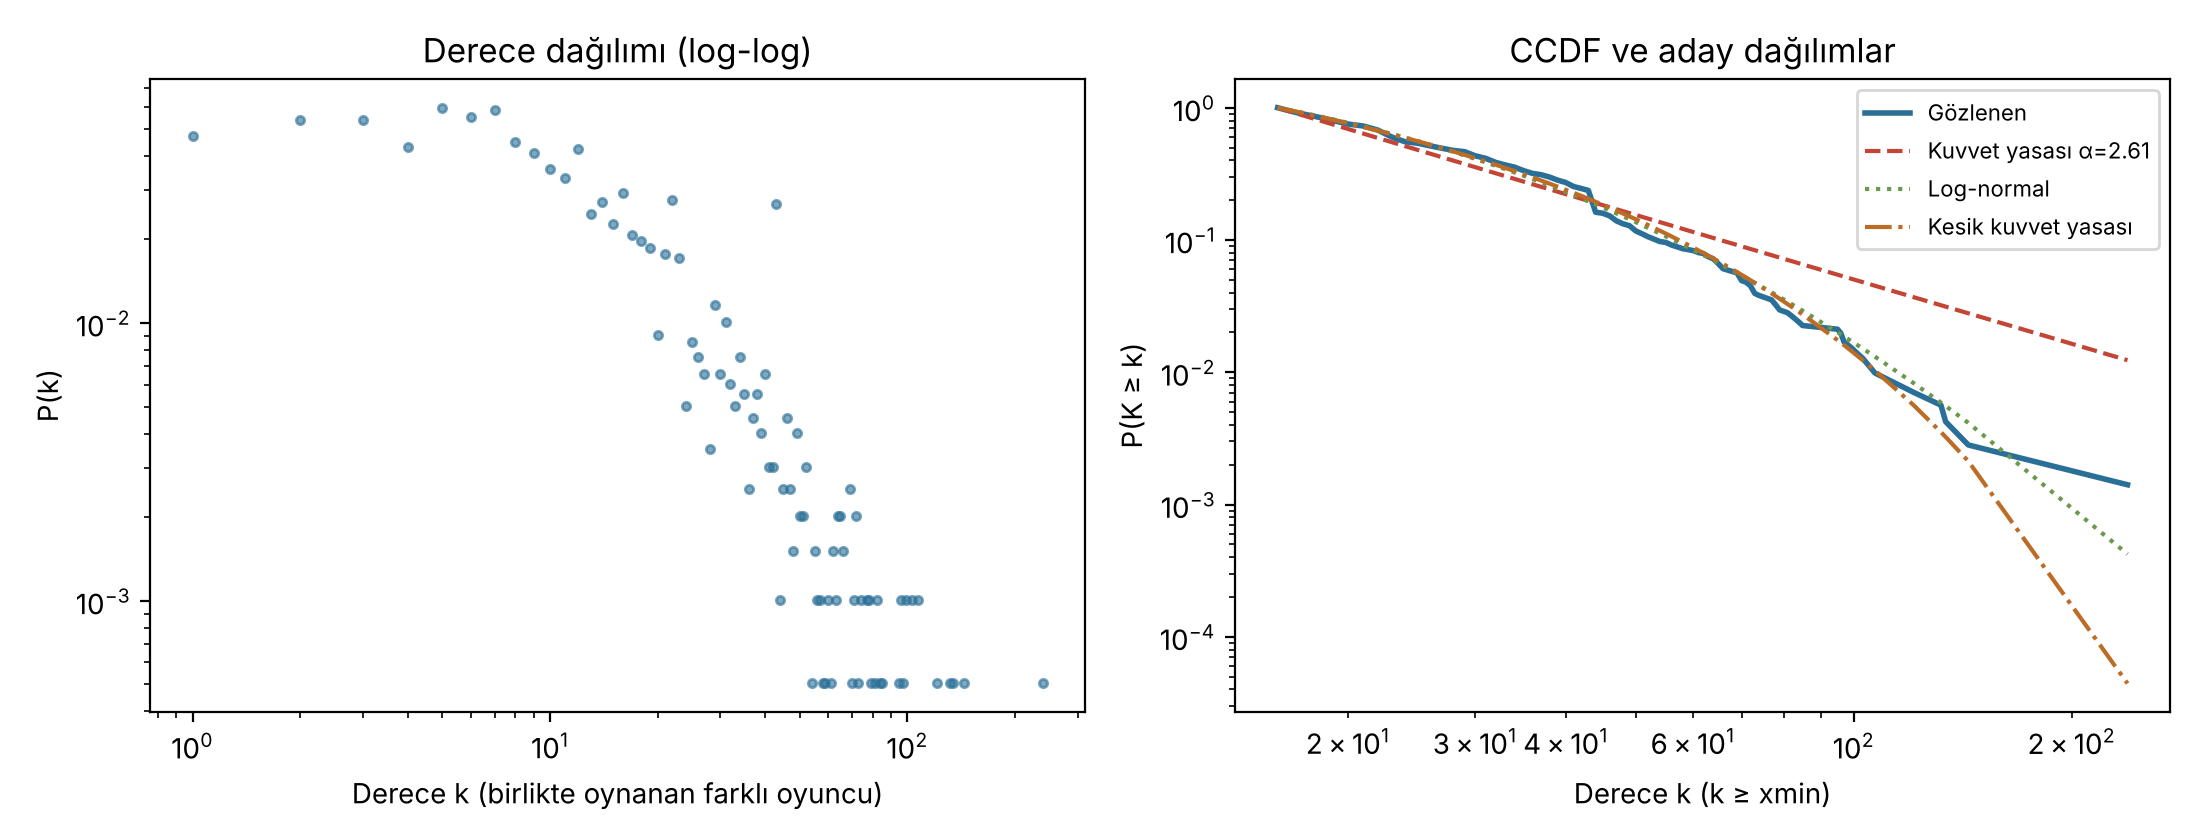

,R,p,yorum
lognormal,-4.861284,0.000001,lognormal daha iyi
exponential,-2.577107,0.009963,exponential daha iyi
truncated_power_law,-4.741961,0.0,truncated_power_law daha iyi
stretched_exponential,-4.832983,0.000001,stretched_exponential daha iyi


In [5]:
display(Image(str(KOK/"figures/derece_dagilimi.png")))
pd.DataFrame(t["derece_dagilimi"]["karsilastirma"]).T

In [6]:
for o in ["derece","betweenness","closeness","eigenvector","pagerank"]:
    print("==", o); display(pd.read_csv(KOK/f"results/ilk10_{o}.csv"))
pd.read_csv(KOK/"results/spearman_merkeziyet.csv", index_col=0).round(3)

== derece


,ad,qid,derece,film_sayisi,ilk_yil,son_yil
0,Cüneyt Arkın,Q927967,239,178,1964,2014
1,Güven Kıraç,Q1562315,144,18,1997,2019
2,Altan Erkekli,Q4736145,134,18,2001,2020
3,Ahmet Mümtaz Taylan,Q4696189,132,16,2004,2019
4,Haluk Bilginer,Q470210,121,20,1990,2025
5,Şener Şen,Q388823,107,38,1973,2017
6,İsmail Hacıoğlu,Q8080207,107,14,2001,2019
7,Nubar Terziyan,Q11170397,103,23,1951,1981
8,Nejat İşler,Q3337865,103,14,2004,2024
9,Türkân Şoray,Q447589,99,72,1961,2007


== betweenness


,ad,qid,betweenness,film_sayisi,ilk_yil,son_yil
0,Cüneyt Arkın,Q927967,0.121347,178,1964,2014
1,Şener Şen,Q388823,0.043281,38,1973,2017
2,Türkân Şoray,Q447589,0.037902,72,1961,2007
3,Haluk Bilginer,Q470210,0.036032,20,1990,2025
4,Güven Kıraç,Q1562315,0.036010,18,1997,2019
5,Uğur Polat,Q3552827,0.033239,18,1988,2015
6,Serra Yılmaz,Q930862,0.032957,15,1983,2017
7,Tuncel Kurtiz,Q366685,0.027993,20,1966,2013
8,Altan Erkekli,Q4736145,0.027574,18,2001,2020
9,Ufuk Bayraktar,Q15989287,0.022994,7,2006,2017


== closeness


,ad,qid,closeness,film_sayisi,ilk_yil,son_yil
0,Güven Kıraç,Q1562315,0.406710,18,1997,2019
1,Şener Şen,Q388823,0.405974,38,1973,2017
2,Haluk Bilginer,Q470210,0.403781,20,1990,2025
3,Altan Erkekli,Q4736145,0.402694,18,2001,2020
4,Tuncel Kurtiz,Q366685,0.402513,20,1966,2013
5,Cüneyt Arkın,Q927967,0.401432,178,1964,2014
6,Fikret Kuşkan,Q4118493,0.398755,12,1990,2025
7,Nejat İşler,Q3337865,0.397959,14,2004,2024
8,Ahmet Mümtaz Taylan,Q4696189,0.396815,16,2004,2019
9,Tarık Akan,Q2064734,0.396727,70,1971,2009


== eigenvector


,ad,qid,eigenvector,film_sayisi,ilk_yil,son_yil
0,Güven Kıraç,Q1562315,1.000000,18,1997,2019
1,Altan Erkekli,Q4736145,0.999184,18,2001,2020
2,Ahmet Mümtaz Taylan,Q4696189,0.952571,16,2004,2019
3,Nejat İşler,Q3337865,0.754855,14,2004,2024
4,İsmail Hacıoğlu,Q8080207,0.736581,14,2001,2019
5,Çetin Tekindor,Q3446906,0.678245,11,1984,2017
6,Özgü Namal,Q307835,0.626494,8,2004,2009
7,Haluk Bilginer,Q470210,0.624720,20,1990,2025
8,Erkan Can,Q4974942,0.588828,15,1998,2018
9,Taner Birsel,Q6088017,0.577785,17,2001,2024


== pagerank


,ad,qid,pagerank,film_sayisi,ilk_yil,son_yil
0,Cüneyt Arkın,Q927967,0.008197,178,1964,2014
1,Haluk Bilginer,Q470210,0.003565,20,1990,2025
2,Altan Erkekli,Q4736145,0.003536,18,2001,2020
3,Güven Kıraç,Q1562315,0.003455,18,1997,2019
4,Ahmet Mümtaz Taylan,Q4696189,0.003395,16,2004,2019
5,Türkân Şoray,Q447589,0.003227,72,1961,2007
6,Şener Şen,Q388823,0.003047,38,1973,2017
7,İsmail Hacıoğlu,Q8080207,0.002983,14,2001,2019
8,Nubar Terziyan,Q11170397,0.002901,23,1951,1981
9,Uğur Polat,Q3552827,0.002803,18,1988,2015


,derece,betweenness,closeness,eigenvector,pagerank,film_sayisi
derece,1.000,0.663,0.749,0.832,0.958,0.594
betweenness,0.663,1.000,0.665,0.608,0.724,0.922
closeness,0.749,0.665,1.000,0.944,0.658,0.622
eigenvector,0.832,0.608,0.944,1.000,0.721,0.563
pagerank,0.958,0.724,0.658,0.721,1.000,0.641
film_sayisi,0.594,0.922,0.622,0.563,0.641,1.000


## 4. Topluluk tespiti ve null model (`04_topluluk_null.py`)
- Louvain ve Leiden (dev bileşen, ağırlıklı), her biri 10 farklı tohumla; modülerlik ve tohumlar arası benzerlik (NMI, ARI).
- En yüksek modülerlikli Leiden bölümü referans alınır; en büyük topluluklar içerdikleri oyuncu ve filmlere bakılarak adlandırılır (`results/topluluk_adlari.json`).
- **Null model:** aynı derece dizisine sahip 100 basit ve bağlı rastgele ağ (Viger–Latapy configuration model); kümelenme, ortalama yol, modülerlik ve assortativity için z-skorları.

In [7]:
calistir("04_topluluk_null.py")
tn = json.loads((KOK/"results/topluluk_null.json").read_text(encoding="utf-8"))
pd.DataFrame({k: tn[k] for k in ["louvain","leiden"]})

Dev bileşen: 1795 düğüm, 14744 kenar
Topluluklar tamam: {'louvain': {'modularite_ort': 0.589817741817362, 'modularite_std': 0.0024707616316446647, 'topluluk_sayisi': [17, 18, 21, 18, 17, 18, 18, 20, 19, 18], 'nmi_ort': 0.6701927223965798, 'nmi_min': 0.5968689542112897, 'ari_ort': 0.5990426996700098, 'ari_min': 0.5096241869830755}, 'leiden': {'modularite_ort': 0.5953757625300987, 'modularite_std': 0.00189991115567644, 'topluluk_sayisi': [18, 19, 17, 19, 19, 19, 18, 18, 19, 18], 'nmi_ort': 0.6790170321327823, 'nmi_min': 0.5906238654880017, 'ari_ort': 0.6088298828124461, 'ari_min': 0.5350655576212147}, 'referans': {'algoritma': 'leiden', 'tohum': 3, 'modularite': 0.5987066810719459, 'topluluk_sayisi': 19}}
  null 10/100
  null 20/100
  null 30/100
  null 40/100
  null 50/100
  null 60/100
  null 70/100
  null 80/100
  null 90/100
  null 100/100
transitivity                 gözlenen=0.3413 null=0.0362±0.0007 z=436.2
ortalama_yerel_kumelenme     gözlenen=0.7108 null=0.0382±0.0015 z=439.4
or

,louvain,leiden
modularite_ort,0.589818,0.595376
modularite_std,0.002471,0.0019
topluluk_sayisi,"[17, 18, 21, 18, 17, 18, 18, 20, 19, 18]","[18, 19, 17, 19, 19, 19, 18, 18, 19, 18]"
nmi_ort,0.670193,0.679017
nmi_min,0.596869,0.590624
ari_ort,0.599043,0.60883
ari_min,0.509624,0.535066


In [8]:
adlar = json.loads((KOK/"results/topluluk_adlari.json").read_text(encoding="utf-8"))
pd.DataFrame([{"topluluk": c["topluluk"], "ad": adlar.get(str(c["topluluk"]),{}).get("tr",""), "boyut": c["boyut"], "film_yili_medyan": c["film_yili_medyan"], "en_bagli": ", ".join(x["ad"] for x in c["en_bagli_10"][:5])} for c in tn["en_buyuk_topluluklar"]])

,topluluk,ad,boyut,film_yili_medyan,en_bagli
0,0,2000'ler ana akım ve dram sineması,388,2011.0,"Altan Erkekli, Ahmet Mümtaz Taylan, Nejat İşle..."
1,1,Yeşilçam çekirdeği (1966–1980),376,1973.0,"Cüneyt Arkın, Nubar Terziyan, Türkân Şoray, Tu..."
2,2,Kemal Sunal – Şener Şen çevresi,185,1986.0,"Şener Şen, İsmail Hacıoğlu, Cezmi Baskın, Kema..."
3,3,"Yeni dönem komedi (Hırsız Var!, Aile Arasında)",164,2011.0,"Haluk Bilginer, Mehmet Ali Erbil, Demet Evgâr,..."
4,4,Uğur Polat – Selma Ergeç çevresi,103,2008.0,"Uğur Polat, Selma Ergeç, Yetkin Dikinciler, Su..."
5,6,Almanya-Türkiye ortak yapımları (diaspora sine...,96,2010.0,"Güven Kıraç, Numan Acar, Adam Bousdoukos, İdil..."


In [9]:
pd.DataFrame(tn["null_model"]["olcular"]).T

,gozlenen,null_ort,null_std,z,null_min,null_maks
transitivity,0.341261,0.036177,0.000699,436.239853,0.034819,0.037563
ortalama_yerel_kumelenme,0.710810,0.038239,0.001531,439.404827,0.034374,0.042608
ortalama_yol,3.442049,2.921498,0.004366,119.216062,2.909656,2.931666
modularite_louvain,0.590703,0.203498,0.002054,188.512491,0.198003,0.208413
assortativity,0.018577,-0.033335,0.005530,9.387435,-0.046657,-0.018624


## 5. Zamansal küçük dünya analizi (`05_zamansal.py`) — zorunlu ileri yöntem
Her on yıl için yalnızca o dönemde çıkan filmlerden oyuncu ağı kurulur; dev bileşende:
- **σ = (C / C_r) / (L / L_r)** (Humphries & Gurney 2008): C ortalama yerel kümelenme, L ortalama en kısa yol (ortalama ayrım derecesi); C_r ve L_r aynı derece dizisine sahip 100 rastgele ağın ortalaması. σ > 1 küçük dünya.
- **ω = L_r / L − C / C_l** (Telesford vd. 2011): C_l aynı düğüm sayısı ve ortalama dereceye sahip halka kafesin kümelenmesi (yaklaşım). ω ≈ 0 küçük dünya, −1'e yakın kafes, +1'e yakın rastgele.
- Dev bileşenin büyümesi: her dilimde ve birikimli ağda dev bileşen payı.

  1950–1959: n=115 C=0.681 Cr=0.1477 L=2.52 Lr=2.37 σ=4.3 ω=-0.081
  1960–1969: n=156 C=0.714 Cr=0.1803 L=2.60 Lr=2.44 σ=3.7 ω=-0.170
  1970–1979: n=312 C=0.705 Cr=0.1762 L=2.70 Lr=2.51 σ=3.7 ω=-0.106
  1980–1989: n=234 C=0.753 Cr=0.1744 L=3.11 Lr=2.57 σ=3.6 ω=-0.305
  1990–1999: n=133 C=0.811 Cr=0.1140 L=3.08 Lr=2.52 σ=5.8 ω=-0.443
  2000–2009: n=597 C=0.812 Cr=0.0671 L=3.05 Lr=2.60 σ=10.3 ω=-0.310
  2010–2019: n=691 C=0.752 Cr=0.0491 L=3.43 Lr=2.85 σ=12.7 ω=-0.273
  2020–2025: n=57 C=0.800 Cr=0.1352 L=3.49 Lr=2.41 σ=4.1 ω=-0.643
       dilim  film  oyuncu  gc_pay      C    C_r      L    L_r   sigma  omega
0  1950–1959    88     125   0.920  0.681  0.148  2.523  2.372   4.335 -0.081
1  1960–1969   247     168   0.929  0.714  0.180  2.596  2.444   3.731 -0.170
2  1970–1979   436     343   0.910  0.705  0.176  2.704  2.509   3.709 -0.106
3  1980–1989   337     277   0.845  0.753  0.174  3.113  2.565   3.556 -0.305
4  1990–1999   114     192   0.693  0.811  0.114  3.081  2.519   5.815 -0

,dilim,film,oyuncu,gc_pay,birikimli_gc_pay,C,C_r,L,L_r,sigma,omega
0,1950–1959,88,125,0.920,0.920,0.681,0.148,2.523,2.372,4.335,-0.081
1,1960–1969,247,168,0.929,0.951,0.714,0.180,2.596,2.444,3.731,-0.170
2,1970–1979,436,343,0.910,0.925,0.705,0.176,2.704,2.509,3.709,-0.106
3,1980–1989,337,277,0.845,0.937,0.753,0.174,3.113,2.565,3.556,-0.305
4,1990–1999,114,192,0.693,0.901,0.811,0.114,3.081,2.519,5.815,-0.443
5,2000–2009,236,684,0.873,0.911,0.812,0.067,3.053,2.595,10.286,-0.310
6,2010–2019,429,852,0.811,0.903,0.752,0.049,3.430,2.846,12.709,-0.273
7,2020–2025,67,288,0.198,0.867,0.800,0.135,3.491,2.408,4.079,-0.643


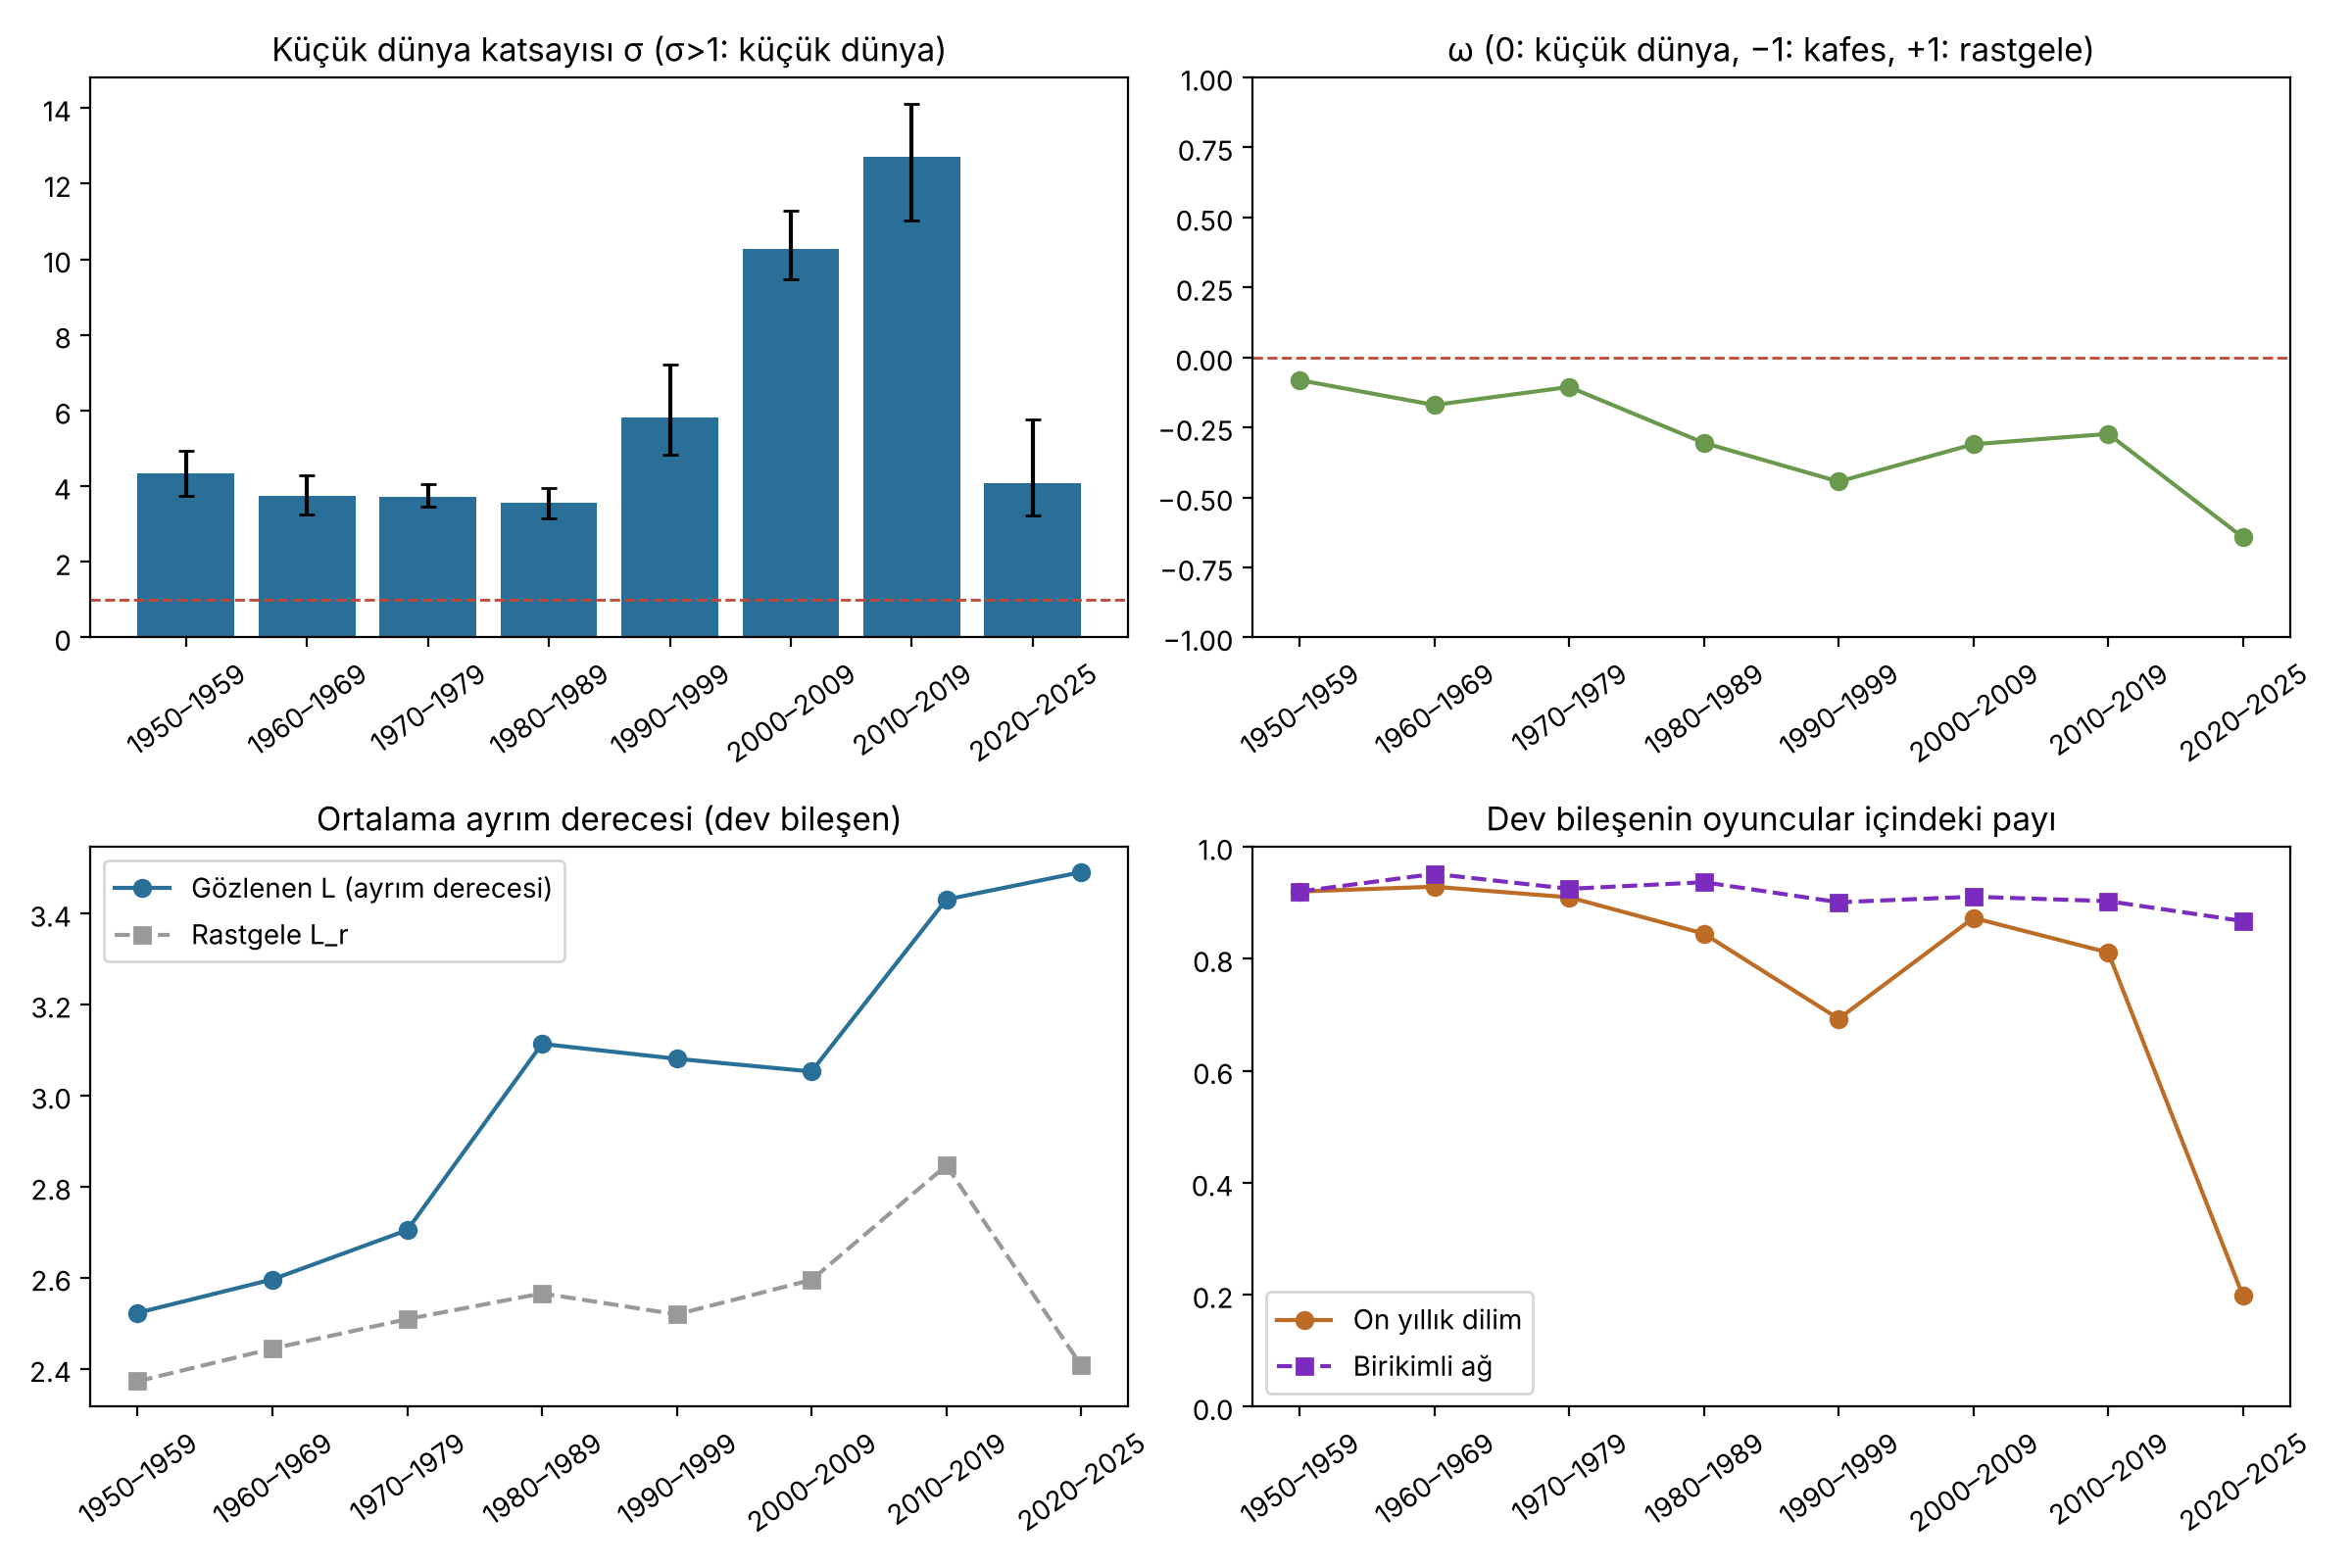

In [10]:
calistir("05_zamansal.py")
z = pd.read_csv(KOK/"results/zamansal_kucuk_dunya.csv")
display(z[["dilim","film","oyuncu","gc_pay","birikimli_gc_pay","C","C_r","L","L_r","sigma","omega"]].round(3))
display(Image(str(KOK/"figures/zamansal_kucuk_dunya.png")))

## 6. Köprü testi (`08_kopru_testi.py`)
Betweenness'ı en yüksek oyuncular dev bileşenden çıkarılınca dev bileşen boyutu ve ortalama ayrım derecesi nasıl değişir? Karşılaştırma: aynı sayıda rastgele oyuncu çıkarma (100 tekrar).

In [11]:
calistir("08_kopru_testi.py")

            ad   gc  kopan     L  L_degisim
  Cüneyt Arkın 1794      0 3.508      0.066
     Şener Şen 1794      0 3.457      0.015
  Türkân Şoray 1794      0 3.458      0.016
Haluk Bilginer 1786      8 3.449      0.007
   Güven Kıraç 1794      0 3.452      0.010
 k                                                                adlar   gc  kopan     L  rastgele_kopan_ort  rastgele_L_ort
 1                                                       [Cüneyt Arkın] 1794      0 3.508                0.14           3.442
 3                              [Cüneyt Arkın, Şener Şen, Türkân Şoray] 1792      0 3.544                0.54           3.443
 5 [Cüneyt Arkın, Şener Şen, Türkân Şoray, Haluk Bilginer, Güven Kıraç] 1782      8 3.563                0.80           3.443



## 7. Görselleştirme (`06_etkilesimli.py`, `07_poster.py`)
- **Etkileşimli ağ** (`docs/index.html`, Sigma.js): arama, detay paneli, topluluk filtresi, TR/EN. Okunurluk için dev bileşenin en bağlantılı 1.200 oyuncusu gösterilir; paneldeki sayılar tüm ağdan hesaplanmıştır.
- **A3 poster** (`figures/poster_A3.pdf`): en bağlantılı 600 oyuncu, Leiden toplulukları, zamansal σ ve ayrım derecesi grafikleri.

docs/index.html: 1200 düğüm, 12663 kenar, 1.0 MB



poster_A3.pdf yazıldı



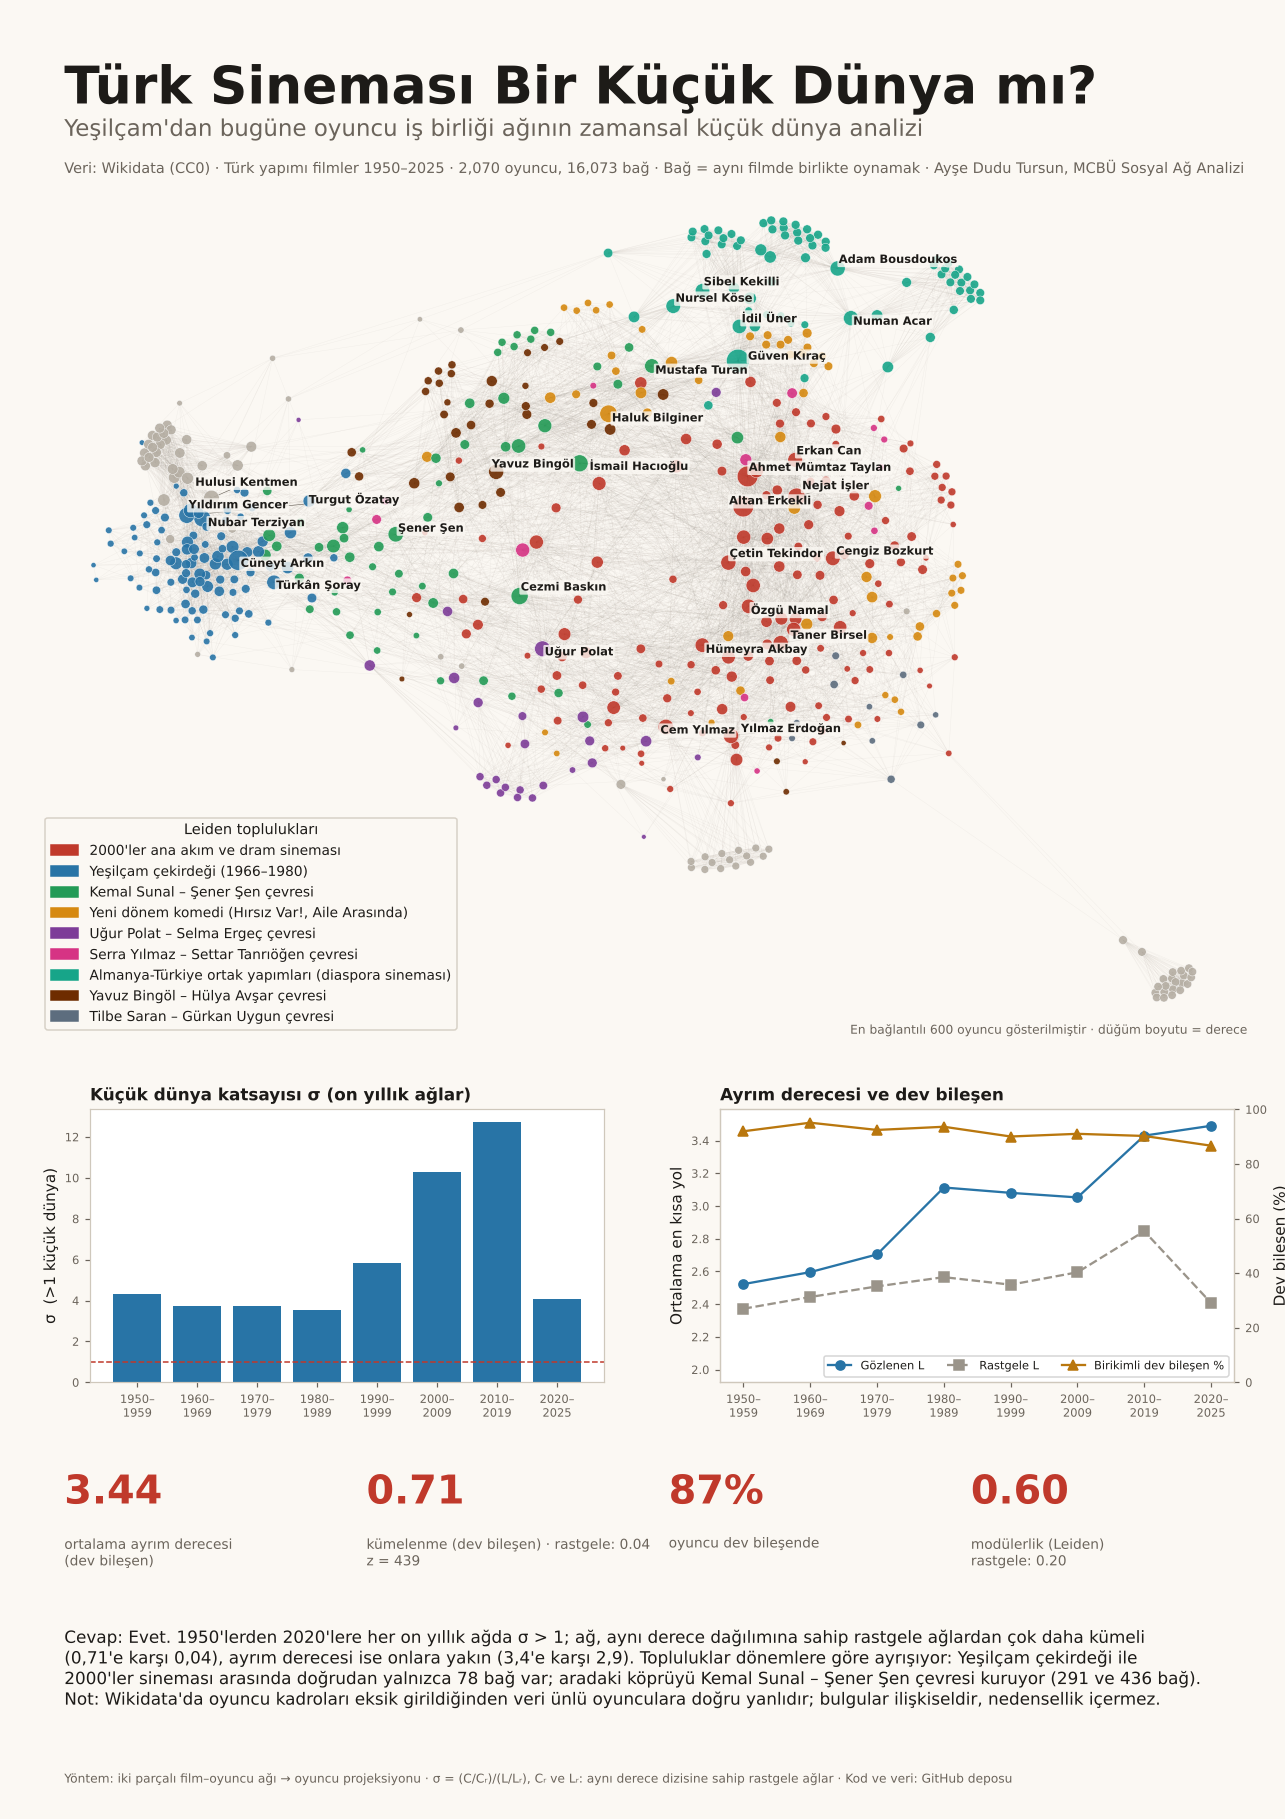

In [12]:
calistir("06_etkilesimli.py")
calistir("07_poster.py")
display(Image(str(KOK/"figures/poster_A3_onizleme.png"), width=600))